Imports et chemins

In [1]:
from pathlib import Path
import random
import shutil
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Project paths
PROJECT_ROOT = Path.cwd().parent

ORIGINAL_DIR = PROJECT_ROOT / "data" / "dataset"
OUTPUT_DIR = PROJECT_ROOT / "data" / "yolo_dataset"

TRAIN_DIR = ORIGINAL_DIR / "train"
TEST_DIR = ORIGINAL_DIR / "test"

print("Project root:", PROJECT_ROOT)
print("Original dataset:", ORIGINAL_DIR)
print("Output dataset:", OUTPUT_DIR)

print("Original dataset exists:", ORIGINAL_DIR.exists())
print("Training folder exists:", TRAIN_DIR.exists())
print("Test folder exists:", TEST_DIR.exists())

Project root: c:\Users\wiwir\plate-recognition
Original dataset: c:\Users\wiwir\plate-recognition\data\dataset
Output dataset: c:\Users\wiwir\plate-recognition\data\yolo_dataset
Original dataset exists: True
Training folder exists: True
Test folder exists: True


Vérifier les fichiers

In [2]:
train_images = sorted(TRAIN_DIR.glob("*.jpg"))
test_images = sorted(TEST_DIR.glob("*.jpg"))

train_xml = sorted(TRAIN_DIR.glob("*.xml"))
test_xml = sorted(TEST_DIR.glob("*.xml"))

print("Training images:", len(train_images))
print("Training annotations:", len(train_xml))

print("Test images:", len(test_images))
print("Test annotations:", len(test_xml))

Training images: 567
Training annotations: 567
Test images: 142
Test annotations: 142


Vérifier les correspondances

In [3]:
def check_matching_files(folder):

    images = {file.stem for file in folder.glob("*.jpg")}
    annotations = {file.stem for file in folder.glob("*.xml")}

    return {
        "missing_annotations": sorted(images - annotations),
        "missing_images": sorted(annotations - images)
    }


print("TRAIN:", check_matching_files(TRAIN_DIR))
print("TEST:", check_matching_files(TEST_DIR))

TRAIN: {'missing_annotations': [], 'missing_images': []}
TEST: {'missing_annotations': [], 'missing_images': []}


Create the output directories

In [4]:
# Create YOLO dataset directories

folders = [
    OUTPUT_DIR / "images" / "train",
    OUTPUT_DIR / "images" / "val",
    OUTPUT_DIR / "images" / "test",

    OUTPUT_DIR / "labels" / "train",
    OUTPUT_DIR / "labels" / "val",
    OUTPUT_DIR / "labels" / "test"
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("YOLO dataset directories created successfully!")

YOLO dataset directories created successfully!


Split the original training images

In [7]:
from sklearn.model_selection import train_test_split

# Get all original training image paths
all_train_images = sorted(TRAIN_DIR.glob("*.jpg"))

# Split: 80% training, 20% validation
train_files, val_files = train_test_split(
    all_train_images,
    test_size=0.20,
    random_state=RANDOM_SEED,
    shuffle=True
)

print("Training images:", len(train_files))
print("Validation images:", len(val_files))

Training images: 453
Validation images: 114


Copy the images and their XML annotations

In [8]:
def copy_image_annotation_pairs(files, destination):

    for image_path in files:

        xml_path = image_path.with_suffix(".xml")

        shutil.copy2(
            image_path,
            destination / image_path.name
        )

        shutil.copy2(
            xml_path,
            destination / xml_path.name
        )


# Copy training and validation pairs
copy_image_annotation_pairs(
    train_files,
    OUTPUT_DIR / "images" / "train"
)

copy_image_annotation_pairs(
    val_files,
    OUTPUT_DIR / "images" / "val"
)

# Copy original test pairs without splitting them
test_files = sorted(TEST_DIR.glob("*.jpg"))

copy_image_annotation_pairs(
    test_files,
    OUTPUT_DIR / "images" / "test"
)

print("Files copied successfully!")

Files copied successfully!


Verify the split

In [9]:
for split in ["train", "val", "test"]:

    folder = OUTPUT_DIR / "images" / split

    images = list(folder.glob("*.jpg"))
    annotations = list(folder.glob("*.xml"))

    print(
        f"{split.upper()}: "
        f"{len(images)} images | "
        f"{len(annotations)} XML annotations"
    )

TRAIN: 453 images | 453 XML annotations
VAL: 114 images | 114 XML annotations
TEST: 142 images | 142 XML annotations


Create the conversion function

In [11]:
def convert_voc_to_yolo(xml_path, output_path):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")

    image_width = int(size.findtext("width"))
    image_height = int(size.findtext("height"))

    yolo_annotations = []

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        # Our only class is LP, with ID 0
        if class_name != "LP":
            continue

        box = obj.find("bndbox")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        # Convert coordinates to YOLO format
        x_center = ((xmin + xmax) / 2) / image_width
        y_center = ((ymin + ymax) / 2) / image_height

        box_width = (xmax - xmin) / image_width
        box_height = (ymax - ymin) / image_height

        yolo_annotations.append(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    output_path.write_text(
        "\n".join(yolo_annotations),
        encoding="utf-8"
    )

Convert annotations for all three sets

In [12]:
for split in ["train", "val", "test"]:

    image_dir = OUTPUT_DIR / "images" / split
    label_dir = OUTPUT_DIR / "labels" / split

    xml_files = list(image_dir.glob("*.xml"))

    for xml_path in xml_files:

        output_path = label_dir / f"{xml_path.stem}.txt"

        convert_voc_to_yolo(
            xml_path,
            output_path
        )

    print(
        f"{split.upper()}: "
        f"{len(xml_files)} annotations converted"
    )

TRAIN: 453 annotations converted
VAL: 114 annotations converted
TEST: 142 annotations converted


Verify one converted annotation

In [13]:
sample_label = (
    OUTPUT_DIR / "labels" / "train" /
    f"{train_files[0].stem}.txt"
)

print("Label file:", sample_label.name)
print(sample_label.read_text())

Label file: 259.txt
0 0.377083 0.606250 0.152083 0.101389


Remove temporary XML copies

In [14]:
for split in ["train", "val", "test"]:

    image_dir = OUTPUT_DIR / "images" / split

    for xml_path in image_dir.glob("*.xml"):
        xml_path.unlink()

print("Temporary XML files removed.")

Temporary XML files removed.


Check image-label correspondence

In [15]:
for split in ["train", "val", "test"]:

    image_dir = OUTPUT_DIR / "images" / split
    label_dir = OUTPUT_DIR / "labels" / split

    images = {p.stem for p in image_dir.glob("*.jpg")}
    labels = {p.stem for p in label_dir.glob("*.txt")}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(images - labels))
    print("Missing images:", len(labels - images))


TRAIN
Images: 453
Labels: 453
Missing labels: 0
Missing images: 0

VAL
Images: 114
Labels: 114
Missing labels: 0
Missing images: 0

TEST
Images: 142
Labels: 142
Missing labels: 0
Missing images: 0


Check bounding-box coordinates

In [16]:
invalid_annotations = []

for split in ["train", "val", "test"]:

    label_dir = OUTPUT_DIR / "labels" / split

    for label_path in label_dir.glob("*.txt"):

        lines = label_path.read_text().strip().splitlines()

        if not lines:
            invalid_annotations.append(
                (split, label_path.name, "Empty annotation")
            )
            continue

        for line_number, line in enumerate(lines, start=1):

            values = line.split()

            if len(values) != 5:
                invalid_annotations.append(
                    (split, label_path.name, "Incorrect number of values")
                )
                continue

            class_id, xc, yc, w, h = map(float, values)

            if class_id != 0:
                issue = "Incorrect class ID"

            elif not (0 < xc < 1 and 0 < yc < 1):
                issue = "Invalid center coordinates"

            elif not (0 < w <= 1 and 0 < h <= 1):
                issue = "Invalid box dimensions"

            elif xc - w / 2 < 0 or xc + w / 2 > 1:
                issue = "Box exceeds horizontal image boundaries"

            elif yc - h / 2 < 0 or yc + h / 2 > 1:
                issue = "Box exceeds vertical image boundaries"

            else:
                continue

            invalid_annotations.append(
                (split, label_path.name, issue)
            )

print("Total invalid annotations:", len(invalid_annotations))
print(invalid_annotations[:10])

Total invalid annotations: 1
[('train', '171.txt', 'Box exceeds vertical image boundaries')]


Visualize the converted YOLO annotations

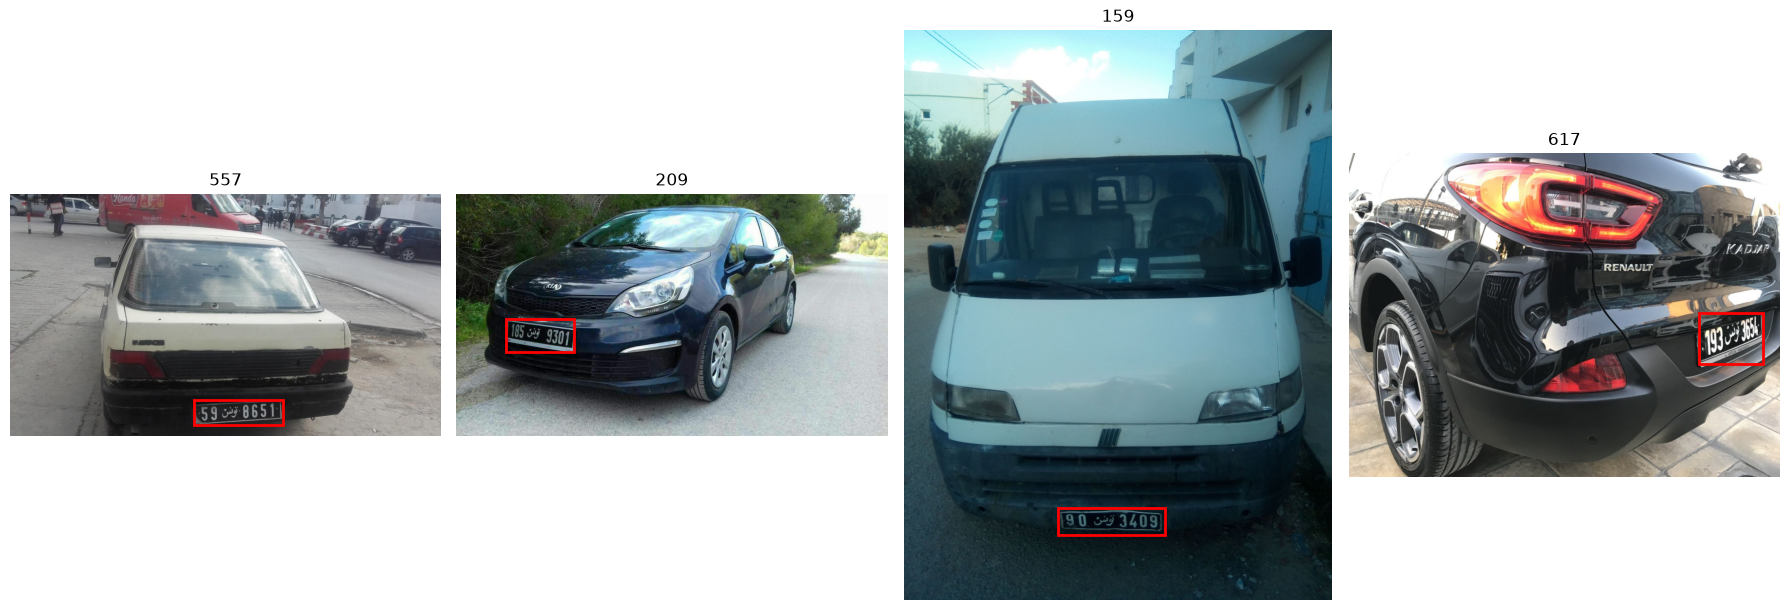

In [17]:
import matplotlib.patches as patches

def display_yolo_annotations(split="train", number=4):

    image_dir = OUTPUT_DIR / "images" / split
    label_dir = OUTPUT_DIR / "labels" / split

    image_files = list(image_dir.glob("*.jpg"))

    selected = random.sample(
        image_files,
        min(number, len(image_files))
    )

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(18, 6)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, selected):

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        height, width = image.shape[:2]

        label_path = label_dir / f"{image_path.stem}.txt"

        ax.imshow(image)

        for line in label_path.read_text().splitlines():

            class_id, xc, yc, w, h = map(float, line.split())

            # Convert normalized coordinates to pixels
            x_center = xc * width
            y_center = yc * height

            box_width = w * width
            box_height = h * height

            xmin = x_center - box_width / 2
            ymin = y_center - box_height / 2

            rectangle = patches.Rectangle(
                (xmin, ymin),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rectangle)
            ax.set_title(image_path.stem)
            ax.axis("off")

    plt.tight_layout()
    plt.show()


display_yolo_annotations("train", 4)